# 01 · Exploratory analysis: who subscribes, when, and what the data cannot be trusted for

**Summary.** 41,188 contacts from May 2008 to November 2010; 11.3% subscribed. The base rate is not stable: it rose from
3% in May 2008 to around 50% in 2010 as the 3-month Euribor fell from 5% to under 1%. Over the same period the bank
called far fewer clients (from 7,763 in May 2008 to about 200 a month), and more of them were warm leads: by 2010, 36%
had been contacted before, against 0.1% in 2008. The famous segment lifts (students and retirees at 2-3x, a previous
"yes" at 65%) are real in the pooled data, but within a single period most of them shrink towards 1x, so much of the
segment story is the calendar and the list. Call duration has the highest IV of any field (1.91; single-feature AUC
0.82), but it is only known after the call, so it is excluded. The macro indicators are legal at call time but act as a
date stamp. The plan that follows: validate out of time, fit with and without macro inputs, and expect calibration
drift.

In [1]:
import os, sys, warnings
os.environ.setdefault("OMP_NUM_THREADS", "4")      # other projects share this laptop: cap OpenMP/BLAS threads
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ds" / "dskit").exists())
sys.path.insert(0, str(ROOT / "ds"))
warnings.simplefilter("ignore")              # library warnings print local paths into the outputs
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dskit import set_style, PALETTE, headline, savefig, audit, eda, evaluate, explain, select, report
import features as F
set_style(); pd.set_option("display.float_format", lambda v: f"{v:,.4f}"); pd.set_option("display.width", 160)
FIG, METRICS, SEED = ROOT / "ds" / "figures", ROOT / "ds" / "reports" / "metrics.json", 42

## 1. Business understanding

| | |
|---|---|
| **Decision** | Which clients to call in the next term-deposit campaign, and how many times to try each one |
| **Unit** | One client in one campaign (the file keeps the client's last contact of that campaign) |
| **Target** | `y`: the client subscribed to a term deposit by the end of the campaign |
| **Action** | Rank the call list by predicted propensity; stop calling a client after N attempts |
| **Success metric** | Net value per campaign = subscriptions x margin per deposit - calls x cost per call; operationally, subscriptions per 100 calls |
| **Constraints** | Fixed call-centre capacity; repeat calls annoy clients (an attempt cap is also a conduct control); only information known before dialling can drive the list; the interest-rate backdrop is outside the bank's control |

The published report already makes one recommendation from this data: **capping calls at five per client cuts 15% of
calls and keeps 96% of subscriptions.** The notebooks keep that number and add the missing half: whom to call first.

## 2. Audit

The file is loaded with the ETL's own `load()`; the year is rebuilt from row order exactly as the ETL does it
(the file is date-ordered from May 2008 to November 2010, so the year increments whenever the month number falls).

In [2]:
df = F.load()
assert len(df) == 41188 and df["call_month"].min() == pd.Timestamp("2008-05-01") and df["call_month"].max() == pd.Timestamp("2010-11-01")
y = df[F.TARGET]
print(f"{len(df):,} contacts, {df.shape[1]} columns, {df['call_month'].nunique()} call months ({df['call_month'].min():%b %Y} - {df['call_month'].max():%b %Y}); "
      f"subscription rate {y.mean():.2%}")
audit.profile(df.drop(columns=["y"]))

41,188 contacts, 24 columns, 26 call months (May 2008 - Nov 2010); subscription rate 11.27%


,dtype,non_null,missing_pct,unique,min,median,max,top,zeros_pct
column,,,,,,,,,
age,int64,41188,0.0000,78,17,38.0000,98,NaN,0.0000
job,str,41188,0.0000,12,None,NaN,None,admin.,NaN
marital,str,41188,0.0000,4,None,NaN,None,married,NaN
education,str,41188,0.0000,8,None,NaN,None,university.degree,NaN
default,str,41188,0.0000,3,None,NaN,None,no,NaN
housing,str,41188,0.0000,3,None,NaN,None,yes,NaN
loan,str,41188,0.0000,3,None,NaN,None,no,NaN
contact,str,41188,0.0000,2,None,NaN,None,cellular,NaN
month,str,41188,0.0000,10,None,NaN,None,may,NaN


{'rows': 41188, 'exact_duplicate_rows': 12} | rows involved: 24 | subscribers among them: 2


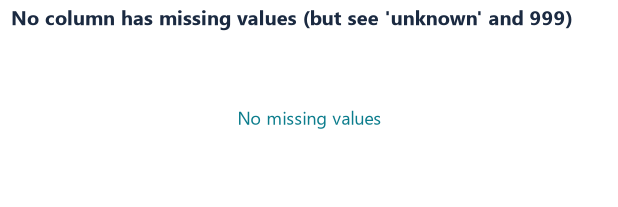

In [3]:
dups = audit.duplicates(df.drop(columns=["year", "call_month"]))
dmask = df.drop(columns=["year", "call_month"]).duplicated(keep=False)
print(dups, f"| rows involved: {dmask.sum()} | subscribers among them: {df.loc[dmask, F.TARGET].sum()}")
fig, ax = plt.subplots(figsize=(7, 1.8)); audit.plot_missing(df, ax=ax, title="No column has missing values (but see 'unknown' and 999)"); plt.show()

There are no NaNs, but missing data is hiding in two places: the text value `unknown` and the number `999`.

In [4]:
unk = pd.DataFrame({c: {"unknown rows": int((df[c] == "unknown").sum()), "share": (df[c] == "unknown").mean(),
                        "rate if unknown": df.loc[df[c] == "unknown", F.TARGET].mean(), "rate if known": df.loc[df[c] != "unknown", F.TARGET].mean()}
                    for c in ["job", "marital", "education", "default", "housing", "loan"]}).T
unk

,unknown rows,share,rate if unknown,rate if known
job,330.0000,0.0080,0.1121,0.1127
marital,80.0000,0.0019,0.1500,0.1126
education,"1,731.0000",0.0420,0.1450,0.1112
default,"8,597.0000",0.2087,0.0515,0.1288
housing,990.0000,0.0240,0.1081,0.1128
loan,990.0000,0.0240,0.1081,0.1128


In [5]:
print("credit default = 'yes':", int((df["default"] == "yes").sum()), "rows")
print("housing and loan unknown on the same rows:", bool(((df["housing"] == "unknown") == (df["loan"] == "unknown")).all()))
pd.crosstab(df["poutcome"], np.where(df["pdays"] == 999, "pdays = 999 (sentinel)", "pdays = days since last contact"), margins=True)

credit default = 'yes': 3 rows
housing and loan unknown on the same rows: True


col_0,pdays = 999 (sentinel),pdays = days since last contact,All
poutcome,,,
failure,4110,142,4252
nonexistent,35563,0,35563
success,0,1373,1373
All,39673,1515,41188


In [6]:
rng_tab = df[["age", "campaign", "pdays", "previous", "duration"] + F.MACRO].describe(percentiles=[0.01, 0.5, 0.99]).T[["min", "1%", "50%", "99%", "max"]]
print(f"Calls of zero seconds: {(df['duration'] == 0).sum()}, subscribed: {df.loc[df['duration'] == 0, F.TARGET].sum()}")
print(f"Clients called more than 10 times in one campaign: {(df['campaign'] > 10).sum():,} ({(df['campaign'] > 10).mean():.1%}); max {df['campaign'].max()}")
rng_tab

Calls of zero seconds: 4, subscribed: 0
Clients called more than 10 times in one campaign: 869 (2.1%); max 56


,min,1%,50%,99%,max
age,17.0000,23.0000,38.0000,71.0000,98.0000
campaign,1.0000,1.0000,2.0000,14.0000,56.0000
pdays,0.0000,3.0000,999.0000,999.0000,999.0000
previous,0.0000,0.0000,0.0000,2.0000,7.0000
duration,0.0000,11.0000,180.0000,"1,271.1300","4,918.0000"
emp.var.rate,-3.4000,-3.4000,1.1000,1.4000,1.4000
cons.price.idx,92.2010,92.2010,93.7490,94.4650,94.7670
cons.conf.idx,-50.8000,-49.5000,-41.8000,-26.9000,-26.9000
euribor3m,0.6340,0.6585,4.8570,4.9680,5.0450
nr.employed,"4,963.6000","4,963.6000","5,191.0000","5,228.1000","5,228.1000"


* **Duplicates:** 12 exact duplicate rows (24 rows involved). With no client ID they could be two clients with identical
  profiles called on the same day, so they stay; they are 0.03% of the data.
* **`unknown` is information, not noise.** Credit-default status is unknown for 21% of clients, and they convert at 5.2%
  against 12.9% when it is known. Only 3 clients have default = "yes", so the field is really "known clean" vs "unknown".
  Housing and personal loan are unknown on exactly the same 990 rows (one missing source record).
* **`pdays = 999` means "never contacted"** for 96% of rows. It is consistent with `poutcome`: every "nonexistent"
  outcome has 999 and every "success" has a real value. But 4,110 of the 4,252 "failure" rows also carry 999, so 999
  really means "no contact date on record", not "never contacted"; `poutcome` and `previous` keep that information.
  Left as a number, 999 would read as "a very long time ago", so it becomes a flag plus a missing value.
* **Ranges are plausible.** Ages 17-98; up to 56 calls to one client in one campaign (2.1% of clients got more than 10),
  which is the case for an attempt cap. The 4 zero-second calls never converted.

## 3. The base rate moves with the economy (and with the campaign)

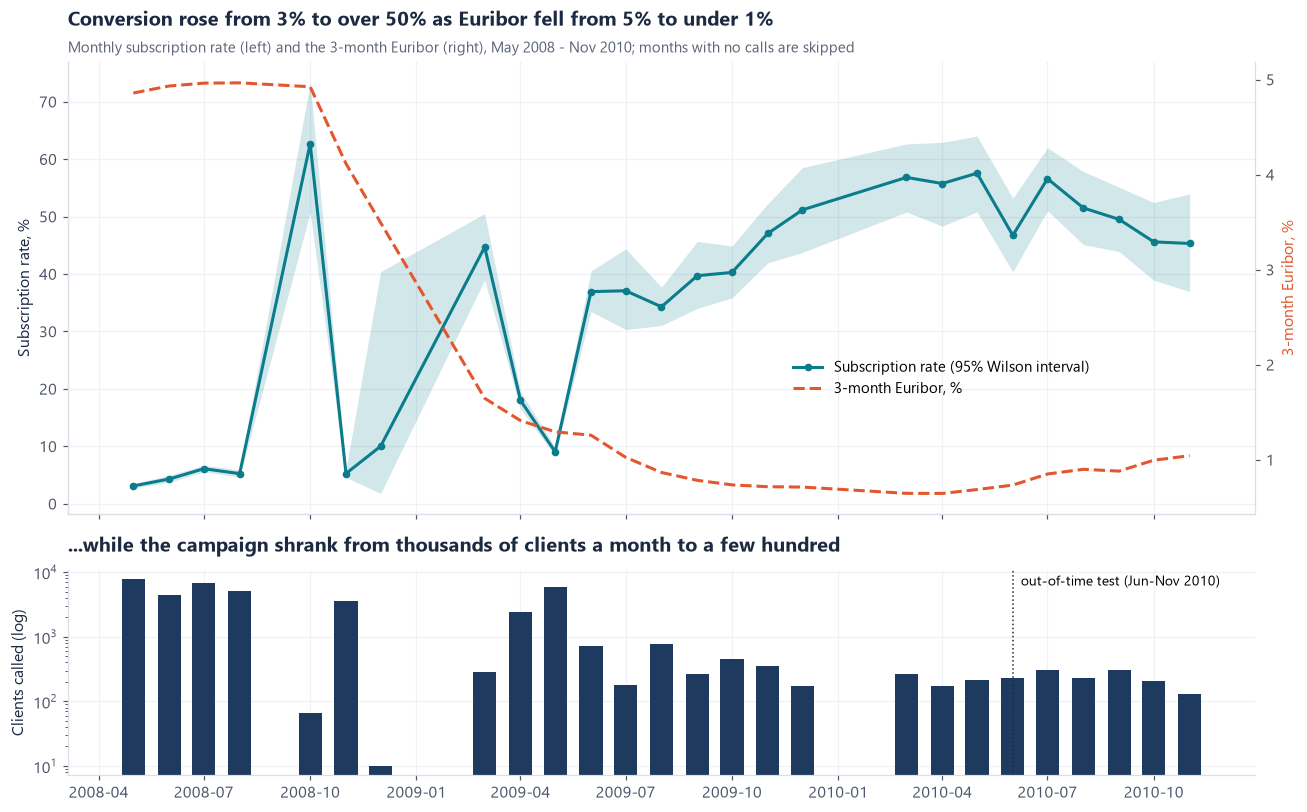

,contacts,rate,euribor,emp_var,calls,prior_contacted
call_month,,,,,,
2008-05-01,7763,0.0309,4.8577,1.1000,19505,0.0000
2008-06-01,4374,0.0430,4.9316,1.4000,14685,0.0000
2008-07-01,6685,0.0609,4.9616,1.4000,21631,0.0000
2008-08-01,5175,0.0524,4.9648,1.4000,14702,0.0000
2008-10-01,67,0.6269,4.9238,-0.1000,67,0.0000
2008-11-01,3616,0.0525,4.1149,-0.1000,6913,0.0097
2008-12-01,10,0.1000,3.4934,-0.2000,10,0.0000
2009-03-01,282,0.4468,1.6462,-1.8000,708,0.0142
2009-04-01,2458,0.1798,1.4117,-1.8000,4758,0.0273


In [7]:
mon = df.groupby("call_month").agg(contacts=(F.TARGET, "size"), rate=(F.TARGET, "mean"), euribor=("euribor3m", "mean"),
                                    emp_var=("emp.var.rate", "mean"), prior=("pdays", lambda s: (s != 999).mean()),
                                    calls=("campaign", "sum"))
lo, hi = eda.wilson(mon["rate"] * mon["contacts"], mon["contacts"])
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
x = mon.index
a1.fill_between(x, lo * 100, hi * 100, color=PALETTE["teal"], alpha=0.18, lw=0)
a1.plot(x, mon["rate"] * 100, marker="o", ms=4, color=PALETTE["teal"], label="Subscription rate (95% Wilson interval)")
a1.set_ylabel("Subscription rate, %")
b1 = a1.twinx(); b1.grid(False); b1.spines["right"].set_visible(True)
b1.plot(x, mon["euribor"], color=PALETTE["coral"], lw=2, ls="--", label="3-month Euribor, %")
b1.set_ylabel("3-month Euribor, %", color=PALETTE["coral"])
h1, l1 = a1.get_legend_handles_labels(); h2, l2 = b1.get_legend_handles_labels(); a1.legend(h1 + h2, l1 + l2, loc="center left", bbox_to_anchor=(0.6, 0.3))
headline(a1, "Conversion rose from 3% to over 50% as Euribor fell from 5% to under 1%",
         "Monthly subscription rate (left) and the 3-month Euribor (right), May 2008 - Nov 2010; months with no calls are skipped")
a2.bar(x, mon["contacts"], width=20, color=PALETTE["navy"])
a2.set_yscale("log"); a2.set_ylabel("Clients called (log)")
a2.axvline(F.TEST_START, color=PALETTE["ink"], lw=1, ls=":"); a2.text(F.TEST_START, mon["contacts"].max() * 0.8, "  out-of-time test (Jun-Nov 2010)", fontsize=9)
headline(a2, "...while the campaign shrank from thousands of clients a month to a few hundred", None)
fig.tight_layout(); _ = savefig(fig, "01-rate-vs-euribor", FIG); plt.show()
mon.assign(prior_contacted=mon["prior"]).drop(columns="prior")

In [8]:
per = pd.cut(df["call_month"], pd.to_datetime(["2008-01-01", "2008-12-01", "2009-06-01", "2010-06-01", "2011-01-01"]), right=False,
             labels=["May-Nov 2008", "Dec 2008-May 2009", "Jun 2009-May 2010", "Jun-Nov 2010 (test)"])
regime = df.groupby(per, observed=True).agg(contacts=(F.TARGET, "size"), rate=(F.TARGET, "mean"), euribor=("euribor3m", "mean"),
                                            emp_var_rate=("emp.var.rate", "mean"), previously_contacted=("pdays", lambda s: (s != 999).mean()),
                                            prior_success=("poutcome", lambda s: (s == "success").mean()), mobile=("contact", lambda s: (s == "cellular").mean()),
                                            calls_per_client=("campaign", "mean"))
regime

,contacts,rate,euribor,emp_var_rate,previously_contacted,prior_success,mobile,calls_per_client
call_month,,,,,,,,
May-Nov 2008,27680,0.0483,4.8176,1.1163,0.0013,0.0013,0.5048,2.8000
Dec 2008-May 2009,8544,0.1279,1.3418,-1.7981,0.0275,0.0259,0.9252,2.2430
Jun 2009-May 2010,3556,0.4232,0.8699,-2.8544,0.2075,0.1884,0.8833,1.8076
Jun-Nov 2010 (test),1408,0.5000,0.8841,-1.4294,0.3601,0.3175,0.7983,1.8885


The rise in conversion is not just the economy. Across the four periods:

* **Euribor** fell from 4.8% to 0.9% and conversion rose from 4.8% to 50%.
* **The list changed at the same time.** Previously contacted clients went from 0.1% to 36% of calls, previous
  successes from 0.1% to 32%, mobile contacts from 50% to 80-92%, and volume fell 20-fold.

The data cannot separate "the economy made deposits attractive" from "the bank started calling its warmest leads". For
the model this means the base rate and the client mix both shift between training and test, and a model validated
with random folds would not notice.

## 4. Who subscribes

Subscription rate with a 95% Wilson interval (line) over the share of contacts (bars), all 41,188 contacts.

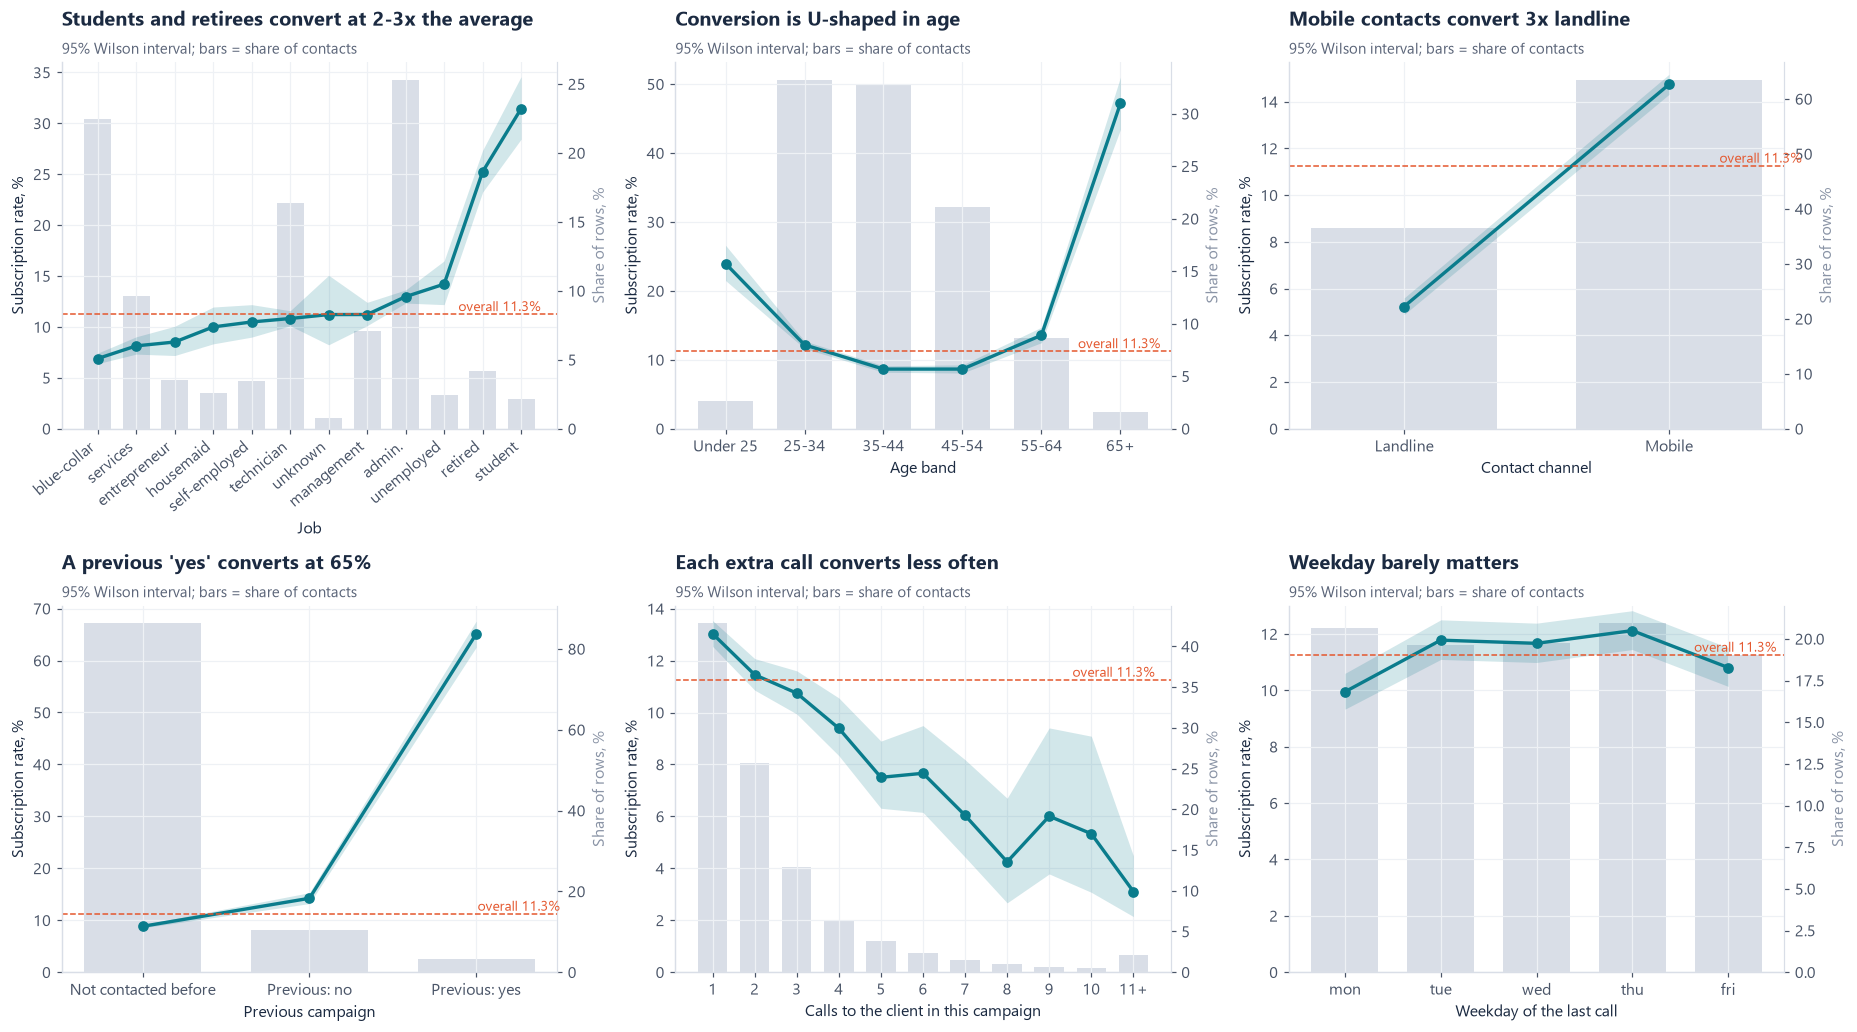

rows   rate  ci_low  ci_high
driver       level                                              
job          blue-collar            9254 0.0689  0.0640   0.0743
             services               3969 0.0814  0.0733   0.0903
             entrepreneur           1456 0.0852  0.0719   0.1006
             housemaid              1060 0.1000  0.0834   0.1195
             self-employed          1421 0.1049  0.0900   0.1219
             technician             6743 0.1083  0.1011   0.1159
             unknown                 330 0.1121  0.0824   0.1507
             management             2924 0.1122  0.1012   0.1241
             admin.                10422 0.1297  0.1234   0.1363
             unemployed             1014 0.1420  0.1219   0.1649
             retired                1720 0.2523  0.2324   0.2734
             student                 875 0.3143  0.2844   0.3458
AgeBand      Under 25               1068 0.2397  0.2151   0.2662
             25-34                 13686 0.1217  0.1164   0.1273
             35-44                 13500 0.0865  0.0819   0.0914
             45-54                  8704 0.0865  0.0808   0.0926
             55-64                  3567 0.1357  0.1248   0.1473
             65+                     663 0.4721  0.4344   0.5101
Channel      Landline              15044 0.0523  0.0489   0.0560
             Mobile                26144 0.1474  0.1431   0.1517
PriorOutcome Not contacted before  35563 0.0883  0.0854   0.0913
             Previous: no           4252 0.1423  0.1321   0.1531
             Previous: yes          1373 0.6511  0.6255   0.6759
Attempt      1                     17642 0.1304  0.1255   0.1354
             2                     10570 0.1146  0.1086   0.1208
             3                      5341 0.1075  0.0994   0.1161
             4                      2651 0.0939  0.0834   0.1056
             5                      1599 0.0750  0.0631   0.0890
             6                       979 0.0766  0.0616   0.0950
             7                       629 0.0604  0.0443   0.0818
             8                       400 0.0425  0.0267   0.0670
             9                       283 0.0601  0.0378   0.0941
             10                      225 0.0533  0.0308   0.0909
             11+                     869 0.0311  0.0214   0.0448
day_of_week  mon                    8514 0.0995  0.0933   0.1060
             tue                    8090 0.1178  0.1110   0.1250
             wed                    8134 0.1167  0.1099   0.1238
             thu                    8623 0.1212  0.1145   0.1282
             fri                    7827 0.1081  0.1014   0.1152

In [9]:
d = df.assign(
    AgeBand=pd.cut(df["age"], [0, 25, 35, 45, 55, 65, 120], right=False, labels=["Under 25", "25-34", "35-44", "45-54", "55-64", "65+"]),
    Channel=df["contact"].map({"cellular": "Mobile", "telephone": "Landline"}),
    PriorOutcome=df["poutcome"].map({"nonexistent": "Not contacted before", "failure": "Previous: no", "success": "Previous: yes"}),
    Attempt=df["campaign"].clip(upper=11).map(lambda v: "11+" if v == 11 else str(v)))
job_order = df.groupby("job")[F.TARGET].mean().sort_values().index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
tabs = {}
spec = [("job", job_order, "Job", "Students and retirees convert at 2-3x the average", 40),
        ("AgeBand", None, "Age band", "Conversion is U-shaped in age", 0),
        ("Channel", None, "Contact channel", "Mobile contacts convert 3x landline", 0),
        ("PriorOutcome", ["Not contacted before", "Previous: no", "Previous: yes"], "Previous campaign", "A previous 'yes' converts at 65%", 0),
        ("Attempt", [str(i) for i in range(1, 11)] + ["11+"], "Calls to the client in this campaign", "Each extra call converts less often", 0),
        ("day_of_week", ["mon", "tue", "wed", "thu", "fri"], "Weekday of the last call", "Weekday barely matters", 0)]
for ax, (col, order, xl, ttl, rot) in zip(axes.flat, spec):
    tabs[col] = eda.rate_by(d, col, F.TARGET, ax=ax, order=order, rate_label="Subscription rate", xlabel=xl, title=ttl,
                            subtitle="95% Wilson interval; bars = share of contacts", rotate=rot, min_n=30)
fig.tight_layout(); _ = savefig(fig, "01-segment-rates", FIG); plt.show()
pd.concat(tabs, names=["driver", "level"])[["rows", "rate", "ci_low", "ci_high"]].round(4)

Pooled over the 30 months, the published picture holds: students (31%) and retirees (25%) convert at 2-3x the 11.3%
average, blue-collar clients at 0.6x (6.9%), mobile contacts at 2.8x landline (14.7% vs 5.2%), and a previous "yes"
at 65%. Conversion falls with every extra call, from 13.0% on the first call to 3.1% beyond the tenth: the economic
case for a cap. Weekday hardly matters (10.0-12.1%).

### Is the segment picture just the calendar in disguise?

Students, retirees, mobile contacts and previous subscribers are all more common in the later, high-conversion months.
If the segment lift only reflects when those clients were called, a model trained on 2008-09 will mis-rank 2010.
Compare each segment's lift against the average of the same period.

In [10]:
d["Period"] = per
lift = []
for col, lv in [("job", "student"), ("job", "retired"), ("job", "blue-collar"), ("Channel", "Mobile"), ("PriorOutcome", "Previous: yes")]:
    for p_, g in d.groupby("Period", observed=True):
        m = g[col] == lv
        if m.sum() >= 30:
            lift.append({"segment": f"{col} = {lv}", "period": p_, "contacts": int(m.sum()), "segment rate": g.loc[m, F.TARGET].mean(),
                         "period rate": g[F.TARGET].mean(), "lift": g.loc[m, F.TARGET].mean() / g[F.TARGET].mean()})
lift = pd.DataFrame(lift)
lift.pivot(index="segment", columns="period", values="lift")[list(per.cat.categories)].round(2)

period,May-Nov 2008,Dec 2008-May 2009,Jun 2009-May 2010,Jun-Nov 2010 (test)
segment,,,,
Channel = Mobile,1.1800,1.0300,1.0300,1.1500
PriorOutcome = Previous: yes,1.7700,3.0800,1.6400,1.5200
job = blue-collar,0.9700,0.6600,0.9500,0.8800
job = retired,1.2200,2.2500,1.0300,1.1100
job = student,1.5000,1.8400,1.1000,0.9400


Within a period the lifts mostly shrink. Students go from 1.5-1.8x in 2008-09 to 0.9x in the test months; retirees
peak at 2.3x in Dec 2008-May 2009 and sit at 1.0-1.2x in every other period. Mobile stays a modest 1.03-1.18x. A previous "yes" keeps a real lift (1.5-3.1x), though it
is capped by the high base rate later on. Much of the pooled segment effect is when those clients were called. That is
exactly what a time-aware validation should expose, and what a random split would hide.

## 5. Information value

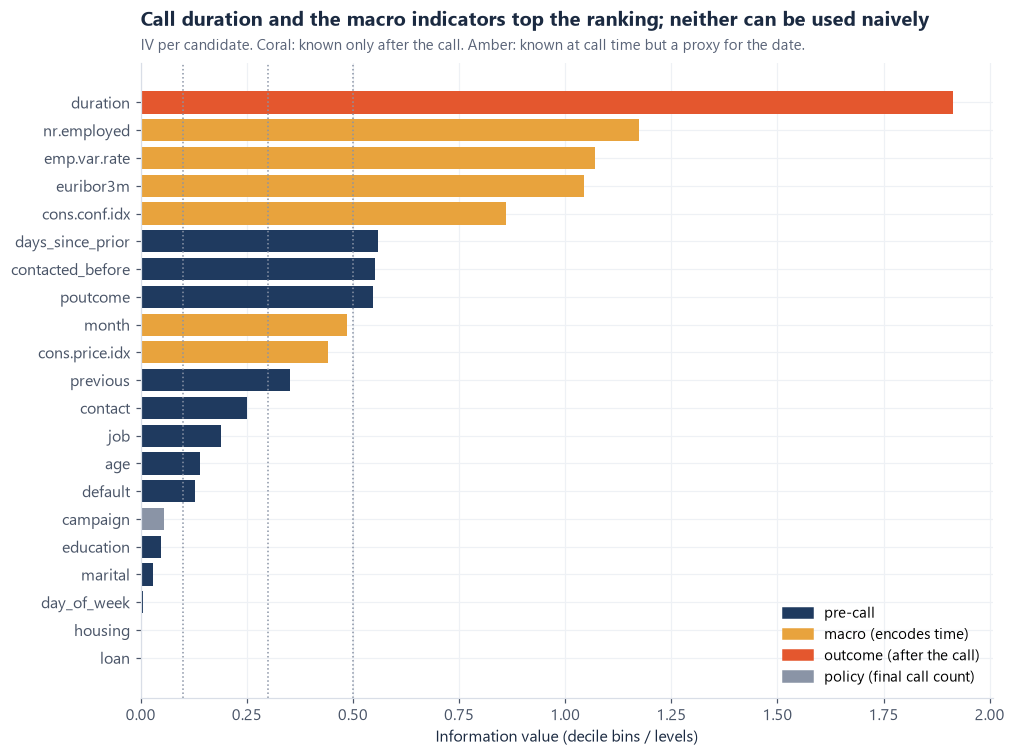

,iv,strength,family
feature,,,
duration,1.9127,suspicious (check leakage),outcome (after the call)
nr.employed,1.1731,suspicious (check leakage),macro (encodes time)
emp.var.rate,1.0699,suspicious (check leakage),macro (encodes time)
euribor3m,1.0447,suspicious (check leakage),macro (encodes time)
cons.conf.idx,0.8601,suspicious (check leakage),macro (encodes time)
days_since_prior,0.5589,suspicious (check leakage),pre-call
contacted_before,0.5514,suspicious (check leakage),pre-call
poutcome,0.5478,suspicious (check leakage),pre-call
month,0.4857,strong,macro (encodes time)


In [11]:
cand = df.assign(contacted_before=(df["pdays"] != 999).astype(int), days_since_prior=df["pdays"].where(df["pdays"] != 999))
cols_iv = F.FEATURES_MACRO + ["campaign", "duration", "month"]
iv = eda.iv_table(cand, cols_iv, F.TARGET)
iv["family"] = ["outcome (after the call)" if c in F.OUTCOME_ONLY else "policy (final call count)" if c in F.POLICY_ONLY else
                "macro (encodes time)" if c in F.MACRO + ["month"] else "pre-call" for c in iv.index]
fig, ax = plt.subplots(figsize=(10, 7.5))
t = iv[::-1]
colr = {"pre-call": PALETTE["navy"], "macro (encodes time)": PALETTE["amber"], "outcome (after the call)": PALETTE["coral"], "policy (final call count)": PALETTE["grey"]}
ax.barh(t.index, t["iv"], color=[colr[f] for f in t["family"]])
for v in (0.1, 0.3, 0.5):
    ax.axvline(v, ls=":", color=PALETTE["grey"], lw=1)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in colr.items()], loc="lower right")
ax.set_xlabel("Information value (decile bins / levels)")
headline(ax, "Call duration and the macro indicators top the ranking; neither can be used naively",
         "IV per candidate. Coral: known only after the call. Amber: known at call time but a proxy for the date.")
_ = savefig(fig, "01-information-value", FIG); plt.show()
iv

## 6. Leakage audit

In [12]:
leak = audit.leakage_screen(cand, cols_iv, F.TARGET, flag_at=0.8)
timing = {"duration": "after the call ends", "campaign": "during the campaign; final value depends on the outcome", "month": "at call time (calendar)",
          **{m: "at call time (published monthly / quarterly)" for m in F.MACRO}, "euribor3m": "at call time (daily market rate)"}
leak["known"] = [timing.get(f, "before the call (client record, previous campaign)") for f in leak.index]
leak.head(12)

,single_feature_auc,direction,review,known
feature,,,,
duration,0.8184,+,CHECK FOR LEAKAGE,after the call ends
nr.employed,0.7490,-,,at call time (published monthly / quarterly)
euribor3m,0.7435,-,,at call time (daily market rate)
emp.var.rate,0.7168,-,,at call time (published monthly / quarterly)
month,0.6581,+,,at call time (calendar)
poutcome,0.6138,+,,"before the call (client record, previous campa..."
cons.price.idx,0.6106,-,,at call time (published monthly / quarterly)
job,0.6103,+,,"before the call (client record, previous campa..."
contact,0.6102,+,,"before the call (client record, previous campa..."


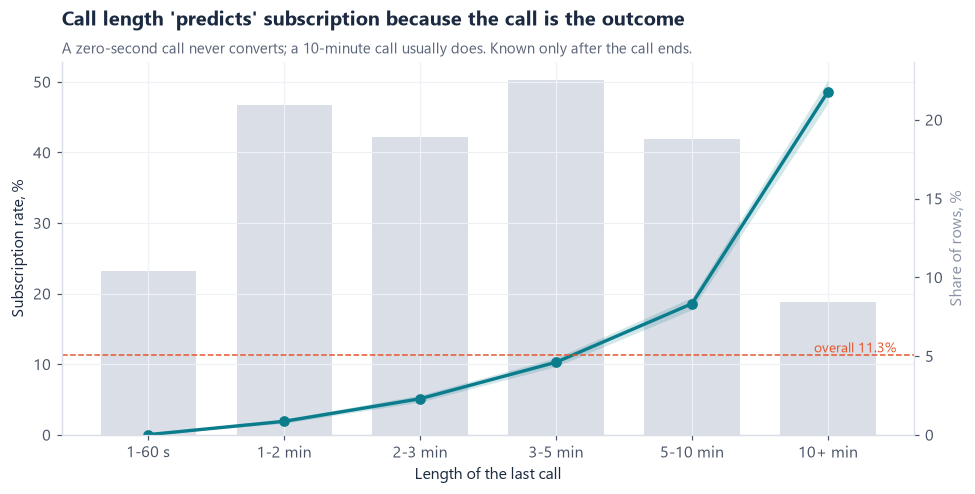

In [13]:
dur = df.assign(DurationBand=pd.cut(df["duration"], [-1, 0, 60, 120, 180, 300, 600, 10_000], labels=["0 s", "1-60 s", "1-2 min", "2-3 min", "3-5 min", "5-10 min", "10+ min"]))
fig, ax = plt.subplots(figsize=(10, 4.4))
t_dur = eda.rate_by(dur, "DurationBand", F.TARGET, ax=ax, rate_label="Subscription rate", xlabel="Length of the last call",
                    title="Call length 'predicts' subscription because the call is the outcome",
                    subtitle="A zero-second call never converts; a 10-minute call usually does. Known only after the call ends.")
plt.show()

* **Duration** has a single-feature AUC of 0.818 on its own and the strongest IV of any field. It is measured after the
  call ends, and a long call is partly the sale itself. A model that uses it would look excellent offline and be useless
  for deciding whom to call. It is reported as an outcome and excluded from every model.
* **Campaign (number of calls)** is known call by call, but the value in the file is the final count, and subscribers
  stop being called once they say yes. It is used by the contact policy (notebook 03), not by the propensity score.
* **Previous-campaign fields** (`poutcome`, `contacted_before`, `days_since_prior`, IV 0.55-0.56) get the IV table's
  "suspicious" label only because a previous "yes" is so predictive. They are on the client record before the call,
  so they stay.
* **Macro indicators** (Euribor, employment variation, CPI, confidence, employed) are legitimate at call time: they are
  published before the calls are made. But they move with the calendar, so together they act as a date stamp.

Distinct macro combinations: 375 for 26 call months; median 14 per month


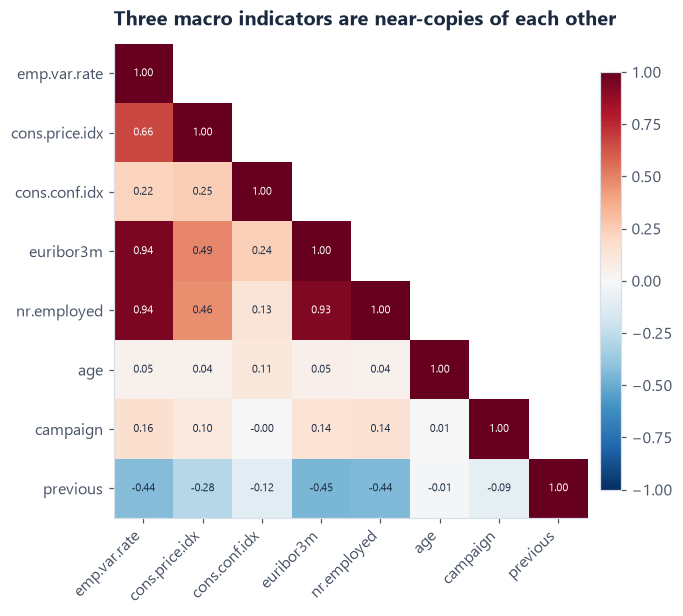

,feature_a,feature_b,rho
1,emp.var.rate,nr.employed,0.9447
0,emp.var.rate,euribor3m,0.9399
2,euribor3m,nr.employed,0.9289


In [14]:
combo = df[F.MACRO].round(4).astype(str).agg("|".join, axis=1)
per_month = combo.groupby(df["call_month"]).nunique()
print(f"Distinct macro combinations: {combo.nunique()} for {df['call_month'].nunique()} call months; median {per_month.median():.0f} per month")
fig, ax = plt.subplots(figsize=(7, 5.6))
c = eda.corr_heatmap(df, F.MACRO + ["age", "campaign", "previous"], ax=ax, title="Three macro indicators are near-copies of each other")
plt.show()
eda.high_correlation_pairs(df, F.MACRO, threshold=0.8)

Euribor is quoted daily (316 distinct values), CPI and confidence monthly (26), employment figures quarterly (10-11).
Together they form 375 distinct combinations, a median of 14 per call month: almost a call-date stamp. Euribor,
employment variation and the number employed correlate at 0.93-0.94 (Spearman), so they carry one signal, not three.
A model with these inputs can learn "this was a good month" rather than "this is a good client". It will look strong
on any validation that shares months with training, and it will need the next month's macro values, which are known
at call time but describe a world the model may never have seen.

## 7. What EDA changed in the plan

* **Drop duration** from every model (single-feature AUC 0.818, IV 1.91, known only after the call).
* **Keep campaign out of the propensity score**; use it for the attempt-cap policy, where its meaning is exact.
* **Validate out of time.** The base rate moves from 3% to over 50% and the client mix moves with it. Random CV would
  mix 2010 clients into training and flatter the model. The test set is the last six months (Jun-Nov 2010), and
  tuning uses expanding time-ordered folds inside the earlier period.
* **Fit two versions, with and without macro features.** Macro inputs are legal but act as a date stamp; the version
  without them shows how much of the model is "who" rather than "when".
* **Plan for calibration drift.** A model trained when 8% subscribed will under-predict when 50% do. Ranking can
  survive that; expected-value decisions cannot, so notebook 02 tests a recalibration step.
* **Encode the sentinels explicitly**: `pdays = 999` becomes "never contacted" plus a missing days-since value;
  `unknown` stays as its own level (clients with unknown credit-default status convert at 5.2%, against 12.9% when it
  is known).

In [15]:
dur_auc = float(leak.loc["duration", "single_feature_auc"])
report.update_metrics(METRICS, "01_eda", {
    "rows": len(df), "subscription_rate": float(y.mean()), "duplicate_rows": dups["exact_duplicate_rows"],
    "rate_by_period": regime["rate"].to_dict(), "euribor_by_period": regime["euribor"].to_dict(),
    "duration_single_feature_auc": dur_auc, "iv_top": {k: float(v) for k, v in iv["iv"].head(8).items()},
    "pdays_sentinel_share": float((df["pdays"] == 999).mean()), "macro_distinct_combinations": int(combo.nunique()),
})["01_eda"]["subscription_rate"]

0.112654